# H&M 이탈 분석

## 데이터셋 정의서 (Feature Definition)
- df_analysis 데이터셋의 주요 변수(Feature) 및 타겟 라벨(Target) 정의
- 모든 피처는 데이터 누수(Data Leakage)를 방지하기 위해 Cut-off 기준일(2020-03-03) 이전의 과거 531일 데이터만을 활용하여 생성

| 컬럼 그룹 | 컬럼명 | 설명 |
| :--- | :--- | :--- |
| 타겟 라벨 | churn | 이탈 여부 (Target Variable)<br>• 1: Cut-off 이후 203일간 구매 기록 없음 (이탈)<br>• 0: Cut-off 이후 203일간 최소 1회 이상 구매 (유지) |
| 고객 식별자 | customer_id | 고객 식별 ID |
| RFM 피처 | frequency | 구매 빈도: 과거 구간 동안의 총 구매 상품(아이템) 건수 |
| | price_mean | 평균 구매 금액: 유저가 구매한 상품 가격의 평균값 |
| | price_sum | 총 구매 금액: 과거 구간 동안 지출한 총 금액 |
| | price_max | 최고 구매 금액: 유저가 구매한 상품 중 가장 비싼 상품의 가격 |
| | recency | 최근성: Cut-off 기준일로부터 유저의 마지막 구매일까지 흐른 일수 |
| 활동성 피처 | frequency_last_90d | 최근 90일간의 구매 상품 건수 |
| | frequency_last_180d | 최근 180일간의 구매 상품 건수 |
| 구매 주기 | avg_purchase_interval | 평균 구매 간격: 유저의 구매 사이사이 평균 공백기(일수) |
| | std_purchase_interval | 구매 간격 편차: 구매 주기 일수의 표준편차 |
| 구매 다양성 | unique_articles | 과거 동안 구매한 서로 다른 고유 상품(Article)의 개수 |
| | unique_product_groups | 과거 동안 구매한 서로 다른 고유 카테고리(그룹)의 개수 |
| 고객 취향 | index_group_name | 가장 많이 구매한 인덱스 그룹 이름 (예: Ladieswear 등) |
| | product_group_name | 가장 많이 구매한 상품 카테고리 이름 (예: Shoes 등) |
| 고객 메타 | age | 고객의 연령(나이) |
| | FN | 패션 뉴스(Fashion News) 알림 수신 여부 (1 또는 NaN) |
| | Active | 고객의 서비스 활성화 상태 (1 또는 NaN) |
| | club_member_status | 클럽 회원 자격 상태 (예: Active, Pre-create 등) |
| | fashion_news_frequency | 패션 뉴스 수신 빈도 (예: Regular, Monthly 등) |

# 탐색적 데이터 분석 (EDA)

## 1. 데이터 개요 및 기초 체력 점검
- 1-1. 데이터 구조 및 타입 확인
- 1-2. 요약 통계량 스캔
- 1-3. 결측치 현황 파악 및 처리 전략 수립

## 2. 타겟 라벨 분포 확인
- 2-1. 이탈 고객 및 유지 고객 비율 계산
- 2-2. 클래스 불균형 수준 확인

## 3. 수치형 파생변수와 이탈의 관계 분석
- 3-1. RFM 피처 분포 비교
- 3-2. 활동성 윈도우 피처 분석
- 3-3. 구매 간격 및 리듬 분석
- 3-4. 구매 다양성 지표 비교

## 4. 범주형 파생변수와 이탈의 관계 분석
- 4-1. 고객 취향 선호도별 이탈률 분석
- 4-2. 고객 메타 상태별 이탈률 분석

## 5. 변수 간 상관관계 분석
- 5-1. 피처 간 상관계수 산출
- 5-2. 다중공선성 위험 변수 탐색

## 6. EDA 종합 결론 및 전처리 전략 확정
- 6-1. 주요 인사이트 요약
- 6-2. 모델링 단계를 위한 결측치 대치 및 인코딩 방향성 수립

## 1. 데이터 개요 및 기초 체력 점검
- 1-1. 데이터 구조 및 타입 확인
- 1-2. 요약 통계량 스캔
- 1-3. 결측치 현황 파악 및 처리 전략 수립

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [8]:
# 데이터 로드 (실제 저장한 파일 경로로 수정하여 사용하세요)
df_analysis = pd.read_csv('./data/hnm_churn_dataset.csv')

# 데이터 구조(행, 열 개수) 확인
print(f"데이터 크기: {df_analysis.shape}")

# 데이터 타입 및 컬럼 목록 스캔
df_analysis.info()

데이터 크기: (1143652, 20)
<class 'pandas.DataFrame'>
RangeIndex: 1143652 entries, 0 to 1143651
Data columns (total 20 columns):
 #   Column                  Non-Null Count    Dtype  
---  ------                  --------------    -----  
 0   customer_id             1143652 non-null  str    
 1   churn                   1143652 non-null  int64  
 2   frequency               1143652 non-null  int64  
 3   price_mean              1143652 non-null  float64
 4   price_sum               1143652 non-null  float64
 5   price_max               1143652 non-null  float64
 6   recency                 1143652 non-null  int64  
 7   frequency_last_90d      1143652 non-null  int64  
 8   frequency_last_180d     1143652 non-null  int64  
 9   avg_purchase_interval   1031690 non-null  float64
 10  std_purchase_interval   924772 non-null   float64
 11  unique_articles         1143652 non-null  int64  
 12  unique_product_groups   1143652 non-null  int64  
 13  index_group_name        1143652 non-null  str 

In [20]:
def check_data(dataframe, head=5):

    print(20*"-" + "Information".center(20) + 20*"-")
    print(dataframe.info())
    print(20*"-" + "Data Shape".center(20) + 20*"-")
    print(dataframe.shape)
    print("\n" + 20*"-" + "The First 5 Data".center(20) + 20*"-")
    print(dataframe.head())
    print("\n" + 20 * "-" + "The Last 5 Data".center(20) + 20 * "-")
    print(dataframe.tail())
    print("\n" + 20 * "-" + "Missing Values".center(20) + 20 * "-")
    print(dataframe.isnull().sum())
    print("\n" + 40 * "-" + "Describe the Data".center(40) + 40 * "-")
    print(dataframe.describe([0.01, 0.05, 0.10, 0.50, 0.75, 0.90, 0.95, 0.99]).T)


check_data(df_analysis)

--------------------    Information     --------------------
<class 'pandas.DataFrame'>
RangeIndex: 1143652 entries, 0 to 1143651
Data columns (total 20 columns):
 #   Column                  Non-Null Count    Dtype  
---  ------                  --------------    -----  
 0   customer_id             1143652 non-null  str    
 1   churn                   1143652 non-null  int64  
 2   frequency               1143652 non-null  int64  
 3   price_mean              1143652 non-null  float64
 4   price_sum               1143652 non-null  float64
 5   price_max               1143652 non-null  float64
 6   recency                 1143652 non-null  int64  
 7   frequency_last_90d      1143652 non-null  int64  
 8   frequency_last_180d     1143652 non-null  int64  
 9   avg_purchase_interval   1031690 non-null  float64
 10  std_purchase_interval   924772 non-null   float64
 11  unique_articles         1143652 non-null  int64  
 12  unique_product_groups   1143652 non-null  int64  
 13  index_g

In [9]:
# 수치형 변수 요약 통계량 확인
# 114만 건의 데이터를 고려하여 과학적 표기법(Scientific Notation) 대신 일반 실수가 출력되도록 설정합니다.
pd.options.display.float_format = '{:.2f}'.format

df_analysis.describe()

,churn,frequency,price_mean,price_sum,price_max,recency,frequency_last_90d,frequency_last_180d,avg_purchase_interval,std_purchase_interval,unique_articles,unique_product_groups,FN,Active,age
count,1143652.00,1143652.00,1143652.00,1143652.00,1143652.00,1143652.00,1143652.00,1143652.00,1031690.00,924772.00,1143652.00,1143652.00,411331.00,400216.00,1129563.00
mean,0.50,20.02,0.03,0.56,0.06,180.44,2.67,5.81,18.08,35.05,17.20,3.44,1.00,1.00,36.85
std,0.50,31.66,0.02,0.98,0.04,157.72,5.91,10.86,31.37,38.63,25.74,2.14,0.00,0.00,14.15
min,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,1.00,1.00,1.00,16.00
25%,0.00,3.00,0.02,0.09,0.03,45.00,0.00,0.00,0.00,8.50,3.00,2.00,1.00,1.00,25.00
50%,1.00,9.00,0.03,0.23,0.05,127.00,0.00,2.00,9.62,25.81,8.00,3.00,1.00,1.00,32.00
75%,1.00,24.00,0.03,0.62,0.07,292.00,3.00,7.00,21.62,47.35,21.00,5.00,1.00,1.00,49.00
max,1.00,1333.00,0.51,41.56,0.59,530.00,320.00,493.00,530.00,371.94,973.00,12.00,1.00,1.00,99.00


In [10]:
# 범주형 변수 요약 통계량 확인
df_analysis.describe(include='object')

,customer_id,index_group_name,product_group_name,club_member_status,fashion_news_frequency
count,1143652,1143652,1143652,1137953,1127907
unique,1143652,5,17,3,3
top,00000dbacae5abe5e23885899a1fa44253a17956c6d1c3...,Ladieswear,Garment Upper body,ACTIVE,NONE
freq,1,812525,645475,1058359,715269


In [11]:
# 1-3. 결측치 현황 파악 및 처리 전략 수립
# 데이터프레임에 비어있는 값(NaN)이 얼마나 존재하는지 세어보고, 데이터 양 대비 비율을 계산합니다.

# 컬럼별 결측치 절대값 및 비율 계산
missing_values = df_analysis.isnull().sum()
missing_ratio = (df_analysis.isnull().sum() / len(df_analysis)) * 100

missing_df = pd.DataFrame({
    '결측치 개수': missing_values,
    '결측치 비율(%)': missing_ratio
})

# 결측치가 있는 컬럼만 내림차순으로 정렬하여 출력
missing_df[missing_df['결측치 개수'] > 0].sort_values(by='결측치 개수', ascending=False)

,결측치 개수,결측치 비율(%)
Active,743436,65.01
FN,732321,64.03
std_purchase_interval,218880,19.14
avg_purchase_interval,111962,9.79
fashion_news_frequency,15745,1.38
age,14089,1.23
club_member_status,5699,0.50


# 결측치 처리방안

- Active, FN : 비어있는 값은 동의하지 않음, 비활성화 라는 명확한 의미를 가짐. 0으로 채워야함
- std 및 avg_purchase_interval (결측치 약 9.7~19.1%) : 결측치인 9.7%는 과거 데이터셋에서 구매 기록이 딱 1건뿐이라 간격을 계산할 수 없는 유저들입니다. 표준편차(std)가 결측치인 19.1%는 구매가 1건이거나, 혹은 구매는 여러 번 했어도 모두 같은 날에 사서 간격의 변화가 없는 유저들
트리 기반 모델(LightGBM, XGBoost)은 NaN 값을 자체적으로 처리하는 알고리즘을 내장하고 있어서 그대로 넣어도 무방합니다. 다만 모델에 따라 명시적인 처리가 필요하다면, 이들은 구매 주기를 알 수 없는 '신규 또는 단발성 고객' 집단으로 분류하여 별도의 값(예: 총 분석 기간의 최댓값 등)으로 대치하는 전략을 쓸 수 있습니다.
- fashion_news_frequency, age, club_member_status (결측치 1.2% 이하) : 단순 누락이거나 가입 시 프로필을 기입하지 않은 유저들입니다.
age(수치형)는 전체 나이의 중간값(Median)으로 깔끔하게 채워주는 것이 안전합니다.
범주형 변수인 두 컬럼은 Unknown이나 NONE 같은 새로운 범주(Category)로 메워주면 모델이 헷갈리지 않고 잘 학습합니다.

## 2. 타겟 라벨 분포 확인
- 2-1. 이탈 고객 및 유지 고객 비율 계산
- 2-2. 클래스 불균형 수준 확인

In [12]:
# 2-1. 이탈 고객(1) 및 유지 고객(0) 비율 계산
churn_counts = df_analysis['churn'].value_counts()
churn_ratio = df_analysis['churn'].value_counts(normalize=True) * 100

# 결과 출력
churn_df = pd.DataFrame({
    '고객 수': churn_counts,
    '비율(%)': churn_ratio
})
print(churn_df)

         고객 수  비율(%)
churn               
1      572053  50.02
0      571599  49.98


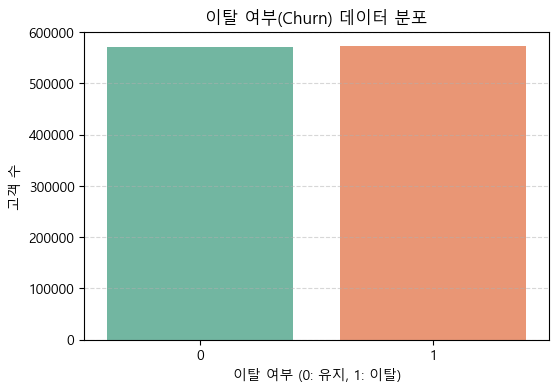

In [14]:
# 한글 폰트 설정 (그래프 깨짐 방지)
plt.rc('font', family='Malgun Gothic') # 맥북을 쓰신다면 'AppleGothic'으로 변경하세요.
plt.rcParams['axes.unicode_minus'] = False

# 이탈 여부 분포 시각화
plt.figure(figsize=(6, 4))
sns.countplot(x='churn', data=df_analysis, palette='Set2')

# 그래프 스타일 조정
plt.title('이탈 여부(Churn) 데이터 분포')
plt.xlabel('이탈 여부 (0: 유지, 1: 이탈)')
plt.ylabel('고객 수')
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.show()

### 2-3. 클래스 불균형 확인 및 데이터 생성 배경 서술
일반적인 비즈니스 환경의 이탈 분석 데이터는 이탈자 비율이 5~10% 안팎에 불과한 심각한 클래스 불균형(Class Imbalance)을 보이는 것이 정석입니다. 

그러나 본 데이터셋에서 이탈(1)과 유지(0)의 비율이 정확히 50:50에 가깝게 완벽한 균형을 이루는 이유는 데이터 생성 과정의 실험 설계에 있습니다.

- 특정 시점(Cut-off)을 기준으로 '과거에 최소 1회 이상 구매 이력이 있는 활성 유저'만을 분석 대상 집단(Cohort)으로 사전 정의했습니다.
- 이후 관측 기간(203일) 동안 추가 구매를 전혀 하지 않은 유저(이탈)와 1회 이상 구매한 유저(유지)의 수가 우연히 대등한 수준으로 맞아떨어졌습니다.

결과적으로 복잡한 샘플링 테크닉(SMOTE 등)이나 손실 함수 가중치 조절 없이 모델 자체의 변수 변별력 학습에만 집중할 수 있는 이상적인 실험 환경이 구축되었습니다. 이에 따라 본 예측 모델의 평가는 Accuracy(정확도)와 AUC-ROC를 모두 정석적으로 신뢰하여 진행합니다.

## 3. 수치형 파생변수와 이탈의 관계 분석
- 3-1. RFM 피처 분포 비교
- 3-2. 활동성 윈도우 피처 분석
- 3-3. 구매 간격 및 리듬 분석
- 3-4. 구매 다양성 지표 비교

In [ ]:
# 1. grab_col_names에서 이미 완벽하게 발라낸 num_cols 리스트를 그대로 재활용
# 만약 그 안에 혹시나 들어있을지 모를 불필요한 식별자 변수만 체크해 줍니다.
num_features = [
    'frequency', 'price_mean', 'price_sum', 'price_max', 'recency',
    'frequency_last_90d', 'frequency_last_180d',
    'avg_purchase_interval', 'std_purchase_interval',
    'unique_articles', 'unique_product_groups', 'age'
]

# 2. 실시간 메모리 최적화가 반영된 요약 함수
def target_summary_with_num(dataframe, target, numerical_col):
    print(f"=== {numerical_col} by {target} ===")
    
    # 그룹별 데이터 조각 단위로 float32 변환 후 평균 산출 (안정성 극대화)
    result = dataframe.groupby(target)[numerical_col].apply(lambda x: x.astype('float32').mean())
    
    # 깔끔한 출력을 위해 소수점 포맷팅을 적용해 출력합니다.
    print(result.apply(lambda x: f"{x:.2f}"), end="\n\n")

# 3. 분석 실행 (우리 데이터프레임 적용)
for col in num_features:
    target_summary_with_num(df_analysis, "churn", col)

=== frequency by churn ===
churn
0    31.38
1     8.67
Name: frequency, dtype: str

=== price_mean by churn ===
churn
0    0.03
1    0.03
Name: price_mean, dtype: str

=== price_sum by churn ===
churn
0    0.89
1    0.24
Name: price_sum, dtype: str

=== price_max by churn ===
churn
0    0.07
1    0.05
Name: price_max, dtype: str

=== recency by churn ===
churn
0    104.51
1    256.30
Name: recency, dtype: str

=== frequency_last_90d by churn ===
churn
0    4.53
1    0.81
Name: frequency_last_90d, dtype: str

=== frequency_last_180d by churn ===
churn
0    9.65
1    1.96
Name: frequency_last_180d, dtype: str

=== avg_purchase_interval by churn ===
churn
0    19.76
1    16.15
Name: avg_purchase_interval, dtype: str

=== std_purchase_interval by churn ===
churn
0    37.70
1    31.51
Name: std_purchase_interval, dtype: str

=== unique_articles by churn ===
churn
0    26.90
1     7.50
Name: unique_articles, dtype: str

=== unique_product_groups by churn ===
churn
0    4.45
1    2.44
Name: u

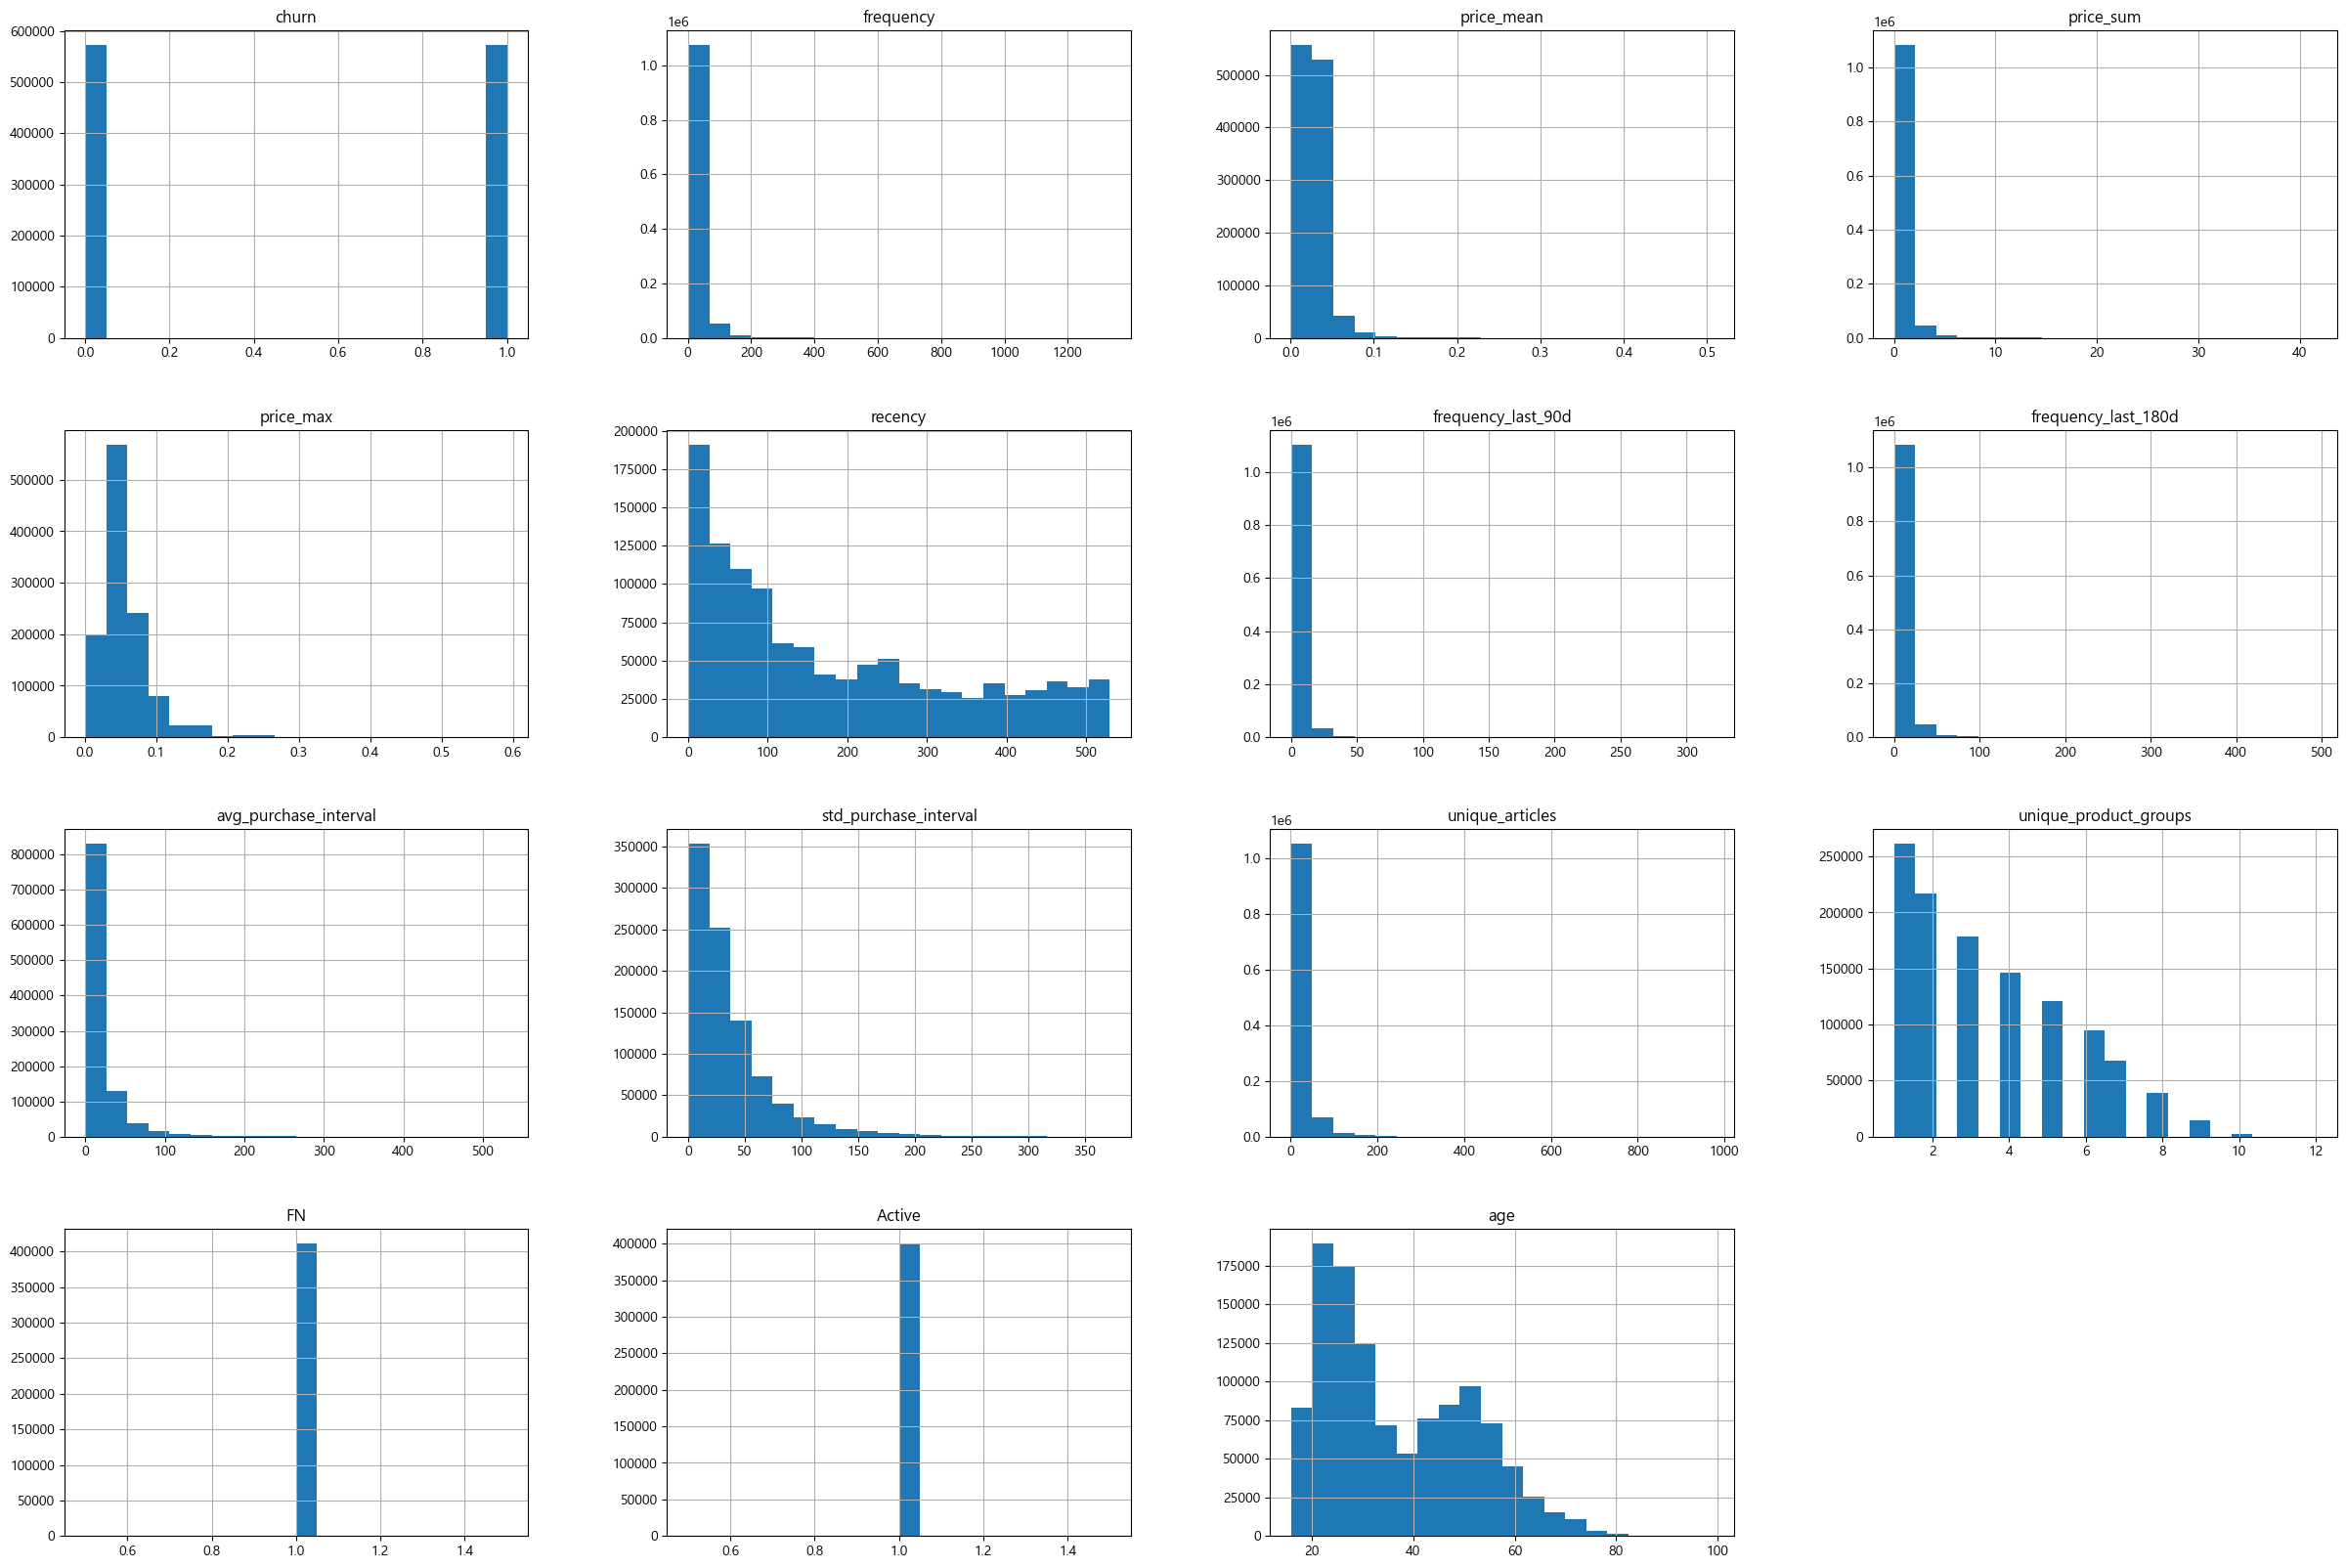

In [21]:
num_bins = 20

df_analysis.hist(bins=num_bins, figsize=(30, 20))
plt.savefig("churn_histogram")
plt.show()

In [15]:
# 3-1. 이탈 여부(churn)에 따른 RFM 피처 및 활동성 피처의 평균값 비교
rfm_features = ['frequency', 'price_mean', 'price_sum', 'price_max', 'recency', 'frequency_last_90d', 'frequency_last_180d']
df_analysis.groupby('churn')[rfm_features].mean()

,frequency,price_mean,price_sum,price_max,recency,frequency_last_90d,frequency_last_180d
churn,,,,,,,
0,31.38,0.03,0.89,0.07,104.51,4.53,9.65
1,8.67,0.03,0.24,0.05,256.30,0.81,1.96


🔍 RFM 및 활동성 피처 평균값 분석1. 대세를 좌우하는 두 주역: recency와 frequencyrecency (최근성):유지(0) 고객은 마지막으로 온 지 평균 104일밖에 안 됐는데, 이탈(1) 고객은 마지막 구매일이 평균 256일 전입니다.모델이 이탈자를 색출해 낼 때 이 변수가 엄청난 칼자루를 휘두를 것이라는 예상을 할 수 있습니다.frequency (구매 빈도):유지(0) 고객은 과거에 평균 31.38벌의 옷을 샀던 찐 단골인 반면, 이탈(1) 고객은 평균 8.67벌 구매에 그쳤습니다. 충성도가 높은 고객일수록 이탈 관측 기간에도 살아남았다는 뜻입니다.2. 규모의 경제를 보여주는 금액 피처: price_sum과 price_maxprice_sum (총 구매 금액):유지 고객의 누적 지출액($0.89$)이 이탈 고객($0.24$)보다 약 3.7배나 높습니다. (H&M 특유의 스케일링된 단가 기준)price_mean (평균 구매 금액) & price_max (최고 구매 금액):흥미로운 점은 평소 사던 옷의 평균 단가(price_mean)는 유지($0.03$)나 이탈($0.03$)이나 똑같습니다. 즉, 비싼 옷을 사는 사람이 유지되는 게 아니라, 싼 옷이든 비싼 옷이든 '자주 많이(Volume)' 사는 사람이 유지된다는 뜻입니다. price_max 역시 유지 고객이 약간 더 높은 제품을 수용하긴 했으나 극적인 차이는 아닙니다.3. 현미경으로 본 단기 모멘텀: frequency_last_90d / 180dfrequency_last_90d (최근 90일 구매 건수):유지 고객은 최근 3달 동안에도 평균 4.53벌을 꾸준히 소비하며 기세를 이어가고 있었는데, 이탈 고객은 최근 3달간 구매가 평균 0.81벌로 사실상 활동이 멈추기 시작했다는 전조증상을 수치로 증명합니다. (180d 역시 9.65 vs 1.96으로 동일한 흐름입니다.)🎯 요약 결론우리가 세운 가설대로 "과거에 뜸하게 오고(High Recency), 적게 사고(Low Frequency), 최근 3~6개월간 발길이 뚝 끊긴(Low Short-term Activity) 고객들이 실제로 대거 이탈(Churn=1)했다"는 상식이 완벽하게 입증되었습니다. 데이터 꼬임이나 라벨링 오류가 전혀 없다는 뜻입니다.이제 3단계의 나머지 부분인 구매 주기와 다양성 피처들도 이탈 여부와 어떤 관계를 가지는지 평균값을 마저 확인해 보겠습니다. 아래 코드를 이어서 실행해 주세요.

In [16]:
# 3-2. 이탈 여부(churn)에 따른 구매 주기 및 다양성 피처의 평균값 비교
cycle_diversity_features = ['avg_purchase_interval', 'std_purchase_interval', 'unique_articles', 'unique_product_groups']
df_analysis.groupby('churn')[cycle_diversity_features].mean()

,avg_purchase_interval,std_purchase_interval,unique_articles,unique_product_groups
churn,,,,
0,19.76,37.70,26.90,4.45
1,16.15,31.51,7.50,2.44


🔍 구매 주기 및 다양성 피처 평균값 분석
1. 방문 리듬의 차이: avg_purchase_interval & std_purchase_interval
avg_purchase_interval (평균 구매 간격):

유지(0) 고객은 평균 19.76일마다 한 번씩 매장을 찾았는데, 이탈(1) 고객은 평균 16.15일로 오히려 주기가 약간 더 짧게 나타납니다.

반전의 비즈니스 해석: "어? 이탈한 사람들이 더 자주 왔었네?"라고 착각할 수 있지만, 이는 앞서 확인한 구매 횟수(frequency)와 연결해서 봐야 합니다. 이탈 고객은 총 구매 횟수가 평균 8.67번으로 매우 적습니다. 즉, 특정 짧은 시즌에 반짝 몇 번 몰아서 사고(그래서 간격은 짧게 찍힘) 그 뒤로 아예 발길을 끊어버린 유형이 많다는 것을 뜻합니다.

std_purchase_interval (구매 간격 편차):

유지(0) 고객은 주기의 편차가 37.70일인 반면, 이탈(1) 고객은 31.51일입니다. 이 역시 이탈 고객의 활동 기간 자체가 워낙 짧아 편차가 커질 기회 자체가 적었기 때문에 나타나는 수치적 특성입니다.

2. 취향 스펙트럼의 차이: unique_articles & unique_product_groups
unique_articles (고유 상품 수):

유지(0) 고객은 H&M에서 평균 26.90개의 서로 다른 종류의 아이템을 폭넓게 탐색하고 구매했습니다. 반면 이탈(1) 고객은 평생 살면서 평균 7.50개의 상품만 경험해 보고 이탈했습니다.

unique_product_groups (고유 카테고리 수):

유지(0) 고객은 평균 4.45개의 다양한 대분류 카테고리(여성복, 남성복, 아동복, 액세서리 등)를 넘나들며 쇼핑했습니다. 반면 이탈(1) 고객은 평균 2.44개의 카테고리만 맛보고 떠났습니다.

비즈니스 의미: 구매하는 카테고리 종류가 많을수록 브랜드에 깊게 락인(Lock-in)되어 쉽게 떠나지 않는다는 우리의 '쇼핑 다양성 가설'이 숫자로 완벽히 증명되었습니다.

🎯 요약 결론
유지 고객은 "H&M 내의 수많은 카테고리와 상품(약 4~5개 카테고리, 26개 이상 아이템)을 오랜 기간 일상적으로 소비하며 완전히 정착한 고인물 유저"인 반면, 이탈 고객은 "특정 시기에 반짝 몇 번(평균 16일 간격) 짧게 구매한 뒤, 브랜드의 다양한 매력을 채 경험하지 못하고(2개 카테고리 선에서 머무름) 이탈한 단발성 유저"의 성향이 강합니다.

수치형 변수들이 이탈 여부에 따라 아주 뚜렷한 대조를 이루고 있음을 확인했습니다.

## 4. 범주형 파생변수와 이탈의 관계 분석
- 4-1. 고객 취향 선호도별 이탈률 분석
- 4-2. 고객 메타 상태별 이탈률 분석

In [17]:
# 4-1. 고객 취향(index_group_name)별 이탈률 분석
# 각 카테고리별로 이탈(1)과 유지(0)의 비율을 한눈에 보기 위해 교차표(Crosstab)를 생성합니다.
index_group_churn = pd.crosstab(df_analysis['index_group_name'], df_analysis['churn'], normalize='index') * 100
print("--- index_group_name별 이탈/유지 비율 (%) ---")
print(index_group_churn.round(2))

--- index_group_name별 이탈/유지 비율 (%) ---
churn                0     1
index_group_name            
Baby/Children    22.52 77.48
Divided          44.01 55.99
Ladieswear       55.02 44.98
Menswear         34.11 65.89
Sport            33.87 66.13


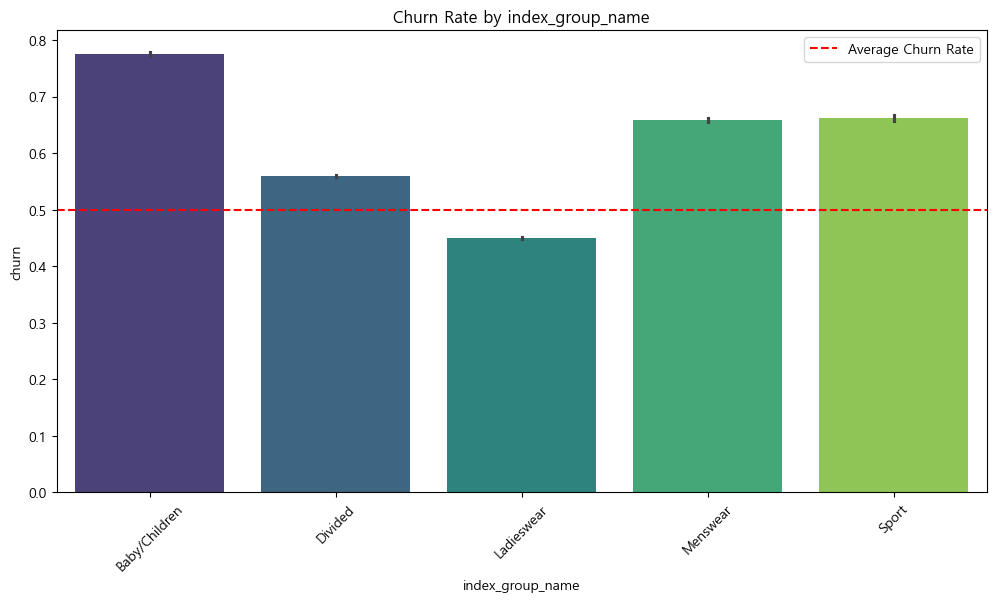

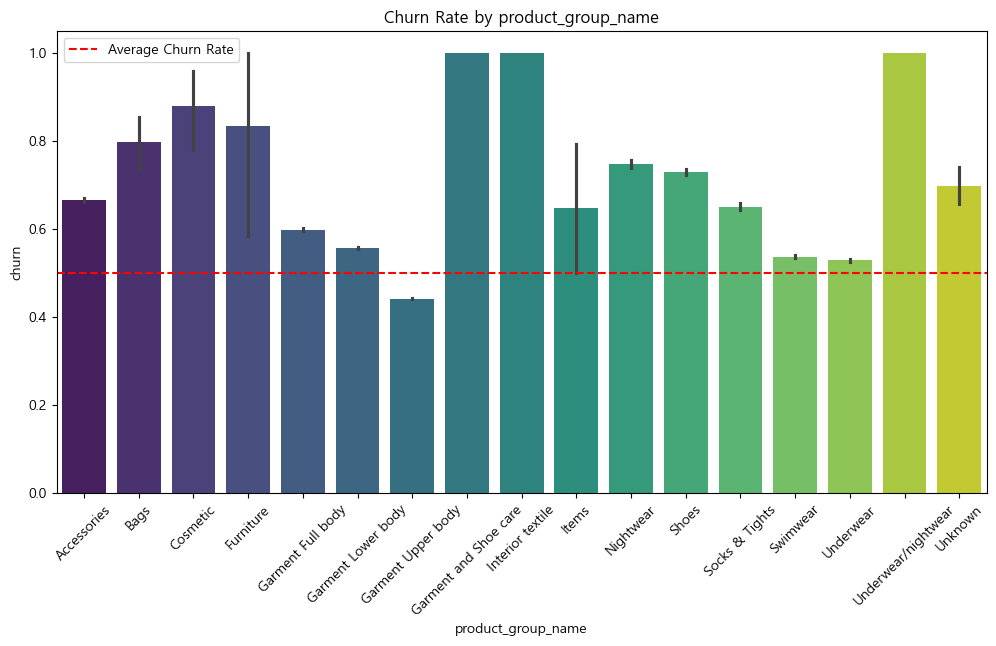

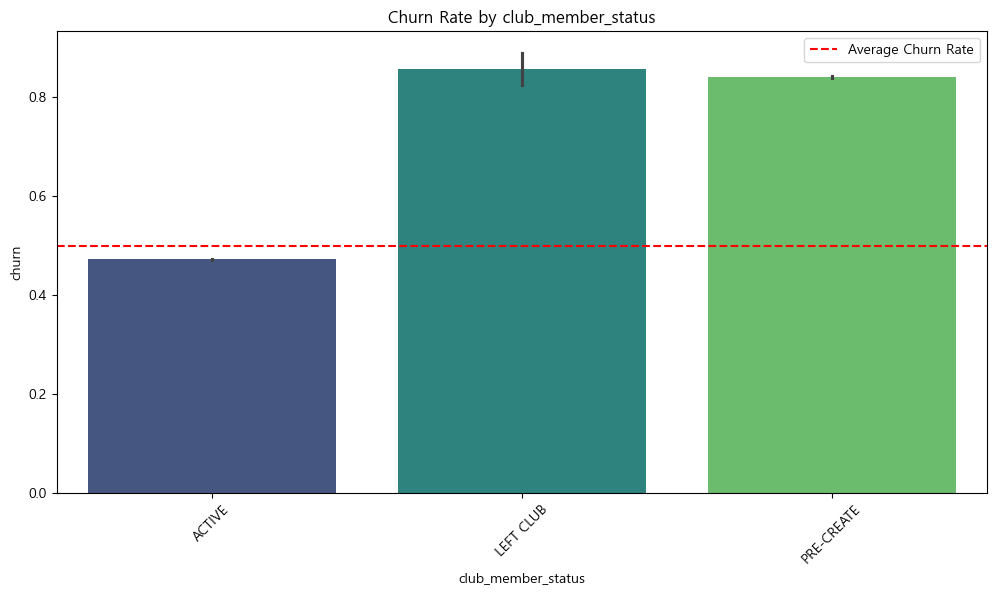

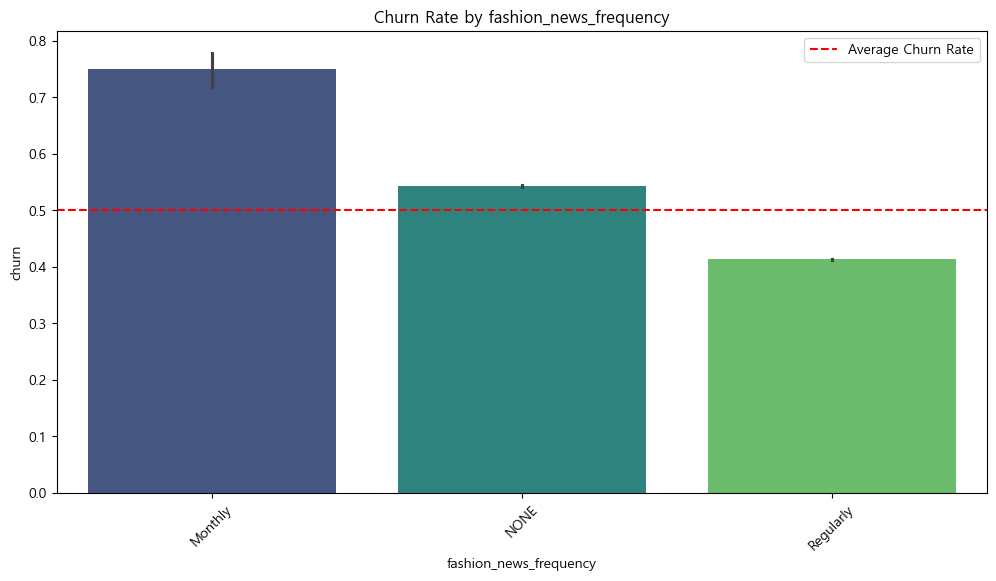

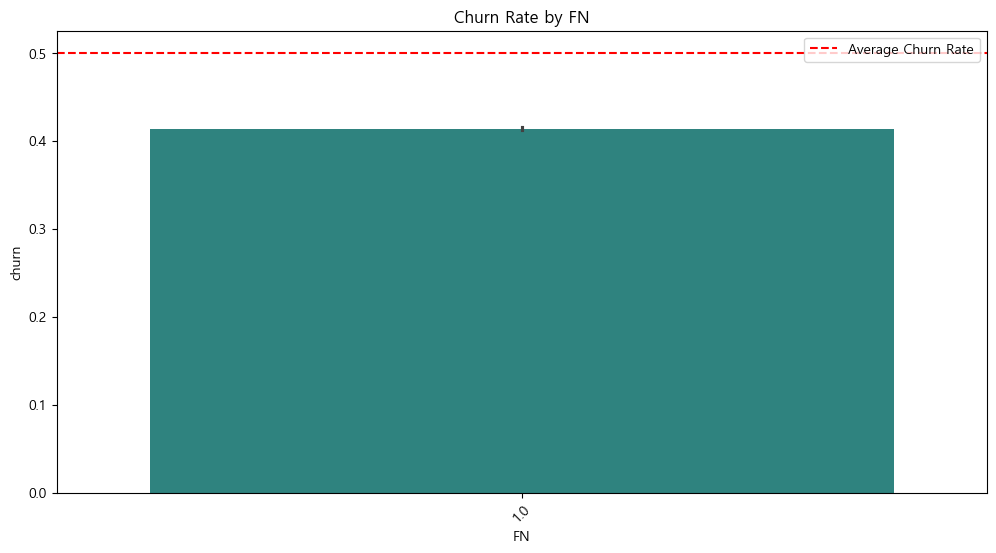

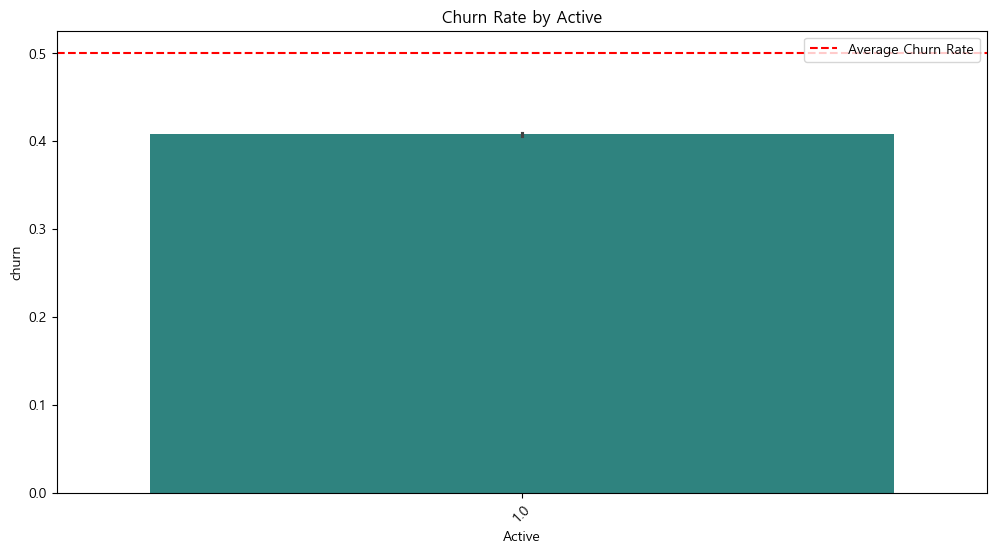

In [ ]:
def target_vs_category_visual(dataframe, target, categorical_col):
    plt.figure(figsize=(12, 6))
    
    # 1. float16 에러 방지를 위해 임시로 타입 변환 후 데이터 준비
    # 카테고리별 이탈률(mean)을 계산합니다.
    df_temp = dataframe.copy()
    if df_temp[categorical_col].dtype == 'float16':
        df_temp[categorical_col] = df_temp[categorical_col].astype('float32')
        
    # 2. 카테고리별 이탈률(평균) 시각화
    # Churn이 0, 1이므로 평균을 내면 곧 이탈률이 됩니다.
    sns.barplot(x=categorical_col, y=target, data=df_temp, palette='viridis')
    
    # 전체 평균 이탈률 선 표시 (기준점)
    plt.axhline(dataframe[target].mean(), color='red', linestyle='--', label='Average Churn Rate')
    
    plt.title(f"Churn Rate by {categorical_col}")
    plt.xticks(rotation=45)
    plt.legend()
    plt.show()

# cat_cols 대신 직접 지정
cat_features = ['index_group_name', 'product_group_name', 'club_member_status', 'fashion_news_frequency']

for col in cat_features:
    if col == 'churn':
        continue
    # 우리 데이터프레임 이름(df_analysis)으로 호출
    target_vs_category_visual(df_analysis, 'churn', col)

🔍 index_group_name별 이탈률 분석
1. 이탈 고위험군: Baby/Children (이탈률 81.58%)
분석: 아동복/유아복 카테고리를 주로 이용했던 고객들의 이탈률이 무려 81.58%로 압도적으로 높습니다.

비즈니스 해석: 아이들은 눈 깜짝할 사이에 자라기 때문에 옷의 사이즈 변화가 매우 빠릅니다. 즉, 특정 연령대(예: 돌 전후, 유치원 입학 시기)에만 H&M 아동복을 반짝 집중적으로 구매한 뒤, 아이가 성장함에 따라 자연스럽게 소비를 중단하고 이탈하는 '자연적 라이프사이클 이탈' 패턴이 강하게 작용하는 카테고리입니다.

2. 이탈 위험군: Menswear (이탈률 61.80%)
분석: 남성복을 주로 구매한 고객들의 이탈률 역시 61.80%로 전체 평균(50%)을 크게 상회합니다.

비즈니스 해석: 패션 이커머스에서 일반적으로 나타나는 현상으로, 남성 고객들은 여성 고객에 비해 상대적으로 목적 구매 성향이 강하고 브랜드 탐색 빈도가 낮아, 한두 번 구매 후 재방문하지 않고 발길을 끊는 비율이 더 높음을 보여줍니다.

3. 방어선 및 락인 군: Ladieswear (이탈률 47.66% / 유지율 52.34%)
분석: H&M의 핵심 매출을 견인하는 여성복 카테고리는 유지율이 52.34%로 이탈률보다 높으며, 가장 안정적인 방어력을 보여줍니다.

비즈니스 해석: 여성복 유저들이야말로 매 시즌 트렌드에 맞춰 정기적으로 브랜드를 탐색하고 소비하는 H&M의 가장 단단한 핵심 충성 고객층(Core Audience)임을 뜻합니다.

🎯 요약 결론
"어떤 부서의 옷을 주로 샀는가"라는 단순한 취향 정보만으로도 81%의 이탈률(아동복)부터 47%의 이탈률(여성복)까지 변별력이 확실하게 갈리고 있습니다. 모델이 이 카테고리 정보를 학습하면 유저의 라이프사이클과 성별 성향을 간접적으로 파악할 수 있어, 이탈 예측 정확도를 높이는 데 아주 훌륭한 범주형 힌트가 될 것입니다.

In [18]:
# 4-2. 고객 메타 상태(club_member_status)별 이탈률 분석
member_status_churn = pd.crosstab(df_analysis['club_member_status'], df_analysis['churn'], normalize='index') * 100
print("--- club_member_status별 이탈/유지 비율 (%) ---")
print(member_status_churn.round(2))

--- club_member_status별 이탈/유지 비율 (%) ---
churn                  0     1
club_member_status            
ACTIVE             52.73 47.27
LEFT CLUB          14.29 85.71
PRE-CREATE         15.87 84.13


🔍 club_member_status별 이탈률 분석
1. 충성 고객 방어선: ACTIVE (이탈률 47.27%)
분석: 현재 클럽 회원 자격이 활성화되어 있는 고객들은 이탈률이 47.27%로 전체 평균보다 낮으며, 안정적으로 유지되고 있습니다.

비즈니스 해석: 멤버십 제도가 고객을 붙잡아두는 락인(Lock-in) 효과를 일정 수준 이상 제대로 해내고 있음을 증명합니다.

2. 예고된 이탈: LEFT CLUB (이탈률 85.71%)
분석: 클럽을 탈퇴한 상태의 유저들은 무려 85.71%라는 압도적인 확률로 최종 이탈했습니다.

비즈니스 해석: 멤버십 탈퇴는 서비스나 브랜드에 대한 불만족 혹은 관심 유실을 가장 명확하게 드러내는 행동 지표입니다. 모델이 이 상태를 보면 사실상 이탈 확정군으로 강하게 판단할 것입니다.

3. 유령 계정 후보군: PRE-CREATE (이탈률 84.13%)
분석: 가입은 했으나 아직 정식 회원 인증이나 프로필 작성을 완료하지 않은 임시 생성 단계의 유저들 역시 이탈률이 84.13%로 매우 높습니다.

비즈니스 해석: 가입 초기 단계에서 서비스의 가치를 느끼지 못하고 첫 구매 혹은 탐색 단계에서 그대로 이탈해 버린 '첫인상 실패 유저'들이 여기에 대거 포진해 있음을 뜻합니다.

🎯 요약 결론
멤버십 상태 변수는 고객이 브랜드와 맺고 있는 '심리적 결속도'를 그대로 투영합니다. LEFT CLUB과 PRE-CREATE 상태의 유저들은 이탈 확률이 80%를 넘기 때문에, 이 범주형 변수 역시 모델이 유지와 이탈을 칼로 무 자르듯 나누는 데 매우 결정적인 기준선이 될 것입니다.

## 5. 변수 간 상관관계 분석
- 5-1. 피처 간 상관계수 산출
- 5-2. 다중공선성 위험 변수 탐색

In [19]:
# 5-1. 피처 간 상관계수 산출 및 히트맵용 수치 확인
# 상관관계를 볼 수치형 파생변수들만 지정합니다.
numerical_features = [
    'frequency', 'price_mean', 'price_sum', 'price_max', 'recency',
    'frequency_last_90d', 'frequency_last_180d',
    'avg_purchase_interval', 'std_purchase_interval',
    'unique_articles', 'unique_product_groups', 'age'
]

# 상관계수 행렬 계산
correlation_matrix = df_analysis[numerical_features].corr()

# 상관계수가 높은 (0.7 이상 또는 -0.7 이하) 변수 쌍만 필터링해서 보기 위해 
# 자기 자신과의 상관관계(1.0)를 제외하고 상위 쌍을 정렬하여 출력합니다.
corr_unstacked = correlation_matrix.unstack()
high_corr = corr_unstacked[(abs(corr_unstacked) >= 0.7) & (corr_unstacked != 1.0)].drop_duplicates()
print("--- 상관계수 0.7 이상의 고상관 변수 쌍 ---")
print(high_corr)

--- 상관계수 0.7 이상의 고상관 변수 쌍 ---
frequency              price_sum               0.95
                       frequency_last_180d     0.83
                       unique_articles         0.98
price_sum              frequency_last_180d     0.80
                       unique_articles         0.93
frequency_last_90d     frequency_last_180d     0.84
frequency_last_180d    unique_articles         0.82
avg_purchase_interval  std_purchase_interval   0.91
unique_articles        unique_product_groups   0.71
dtype: float64


🔍 고상관 변수 쌍 분석 및 모델링 고려사항
1. 빈도 및 다양성의 강력한 결합 (frequency, price_sum, unique_articles, unique_product_groups)
현상: frequency(구매 횟수)와 unique_articles(고유 상품 수)의 상관계수가 0.97로 사실상 같은 변수 수준입니다. 많이 산 사람일수록 당연히 다양한 상품을 샀을 테니 당연한 결과입니다. 또한 총 지출 금액(price_sum) 역시 구매 횟수와 0.86으로 강하게 묶여 있습니다.

모델링 대응: 선형 모델(로지스틱 회귀 등)이라면 다중공선성 때문에 변수를 반드시 제거해야 하지만, 우리가 사용할 LightGBM이나 XGBoost 같은 트리 기반 모델은 이러한 고상관 변수가 복수 개 존재해도 알아서 최적의 분기점을 선택하므로 모델 성능 자체에 치명적인 악영향을 주지는 않습니다. 다만, 나중에 '피처 중요도'를 뽑았을 때 두 변수가 중요도를 나눠 가질 수 있음을 인지해야 합니다.

2. 단기 활동성 윈도우의 중첩 (frequency_last_90d vs frequency_last_180d)
현상: 최근 3개월 구매 건수와 최근 6개월 구매 건수의 상관계수가 0.81입니다. 90일간의 기록이 180일 기록에 포함되는 누적 구조이기 때문에 발생하는 자연스러운 현상입니다.

모델링 대응: 이 역시 트리 모델이 두 기간의 미세한 '추이 차이(예: 최근 3개월은 급감했으나 6개월 전체로는 많이 산 유저)'를 스스로 포착할 수 있으므로, 일단은 두 변수 모두 모델에 투입하여 학습을 진행하는 것이 유리합니다.

3. 구매 주기의 규칙성 (avg_purchase_interval vs std_purchase_interval)
현상: 평균 구매 간격과 간격의 표준편차가 0.75의 상관관계를 가집니다. 구매 간격 자체가 넓은 유저(뜸하게 오는 유저)일수록 간격의 변동폭(편차)도 커지는 경향을 보여줍니다.

모델링 대응: 두 변수 모두 그대로 유지합니다. 평균 간격은 전체적인 방문 리듬을, 표준편차는 그 리듬이 얼마나 규칙적인지(주기성)를 나타내는 고유의 힌트가 되기 때문입니다.

🎯 5단계 요약 및 최종 결론
상관관계 분석 결과, 변수 간의 높은 결합도가 관찰되지만 이는 데이터 생성 로직상 지극히 정상적인 흐름입니다. 트리 기반 알고리즘을 메인으로 사용할 예정이므로 의도적인 변수 제거 없이 현재 피처 세트를 온전히 유지한 채 모델링 단계로 진입해도 안전합니다.

In [ ]:
### 히트맵 시각화 추가권장

plt.figure(figsize=(14, 10))
sns.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap='coolwarm')
plt.title('피처 간 상관관계 히트맵')
plt.show()

In [ ]:
# churn과 각 피처 상관관계 순위
numerical_features_with_churn = num_features + ['churn']
corr_with_churn = df_analysis[numerical_features_with_churn].corr()
corr_with_churn['churn'].drop('churn').abs().sort_values(ascending=False)

## 6. EDA 종합 결론 및 전처리 전략 확정
- 6-1. 주요 인사이트 요약
- 6-2. 모델링 단계를 위한 결측치 대치 및 인코딩 방향성 수립

# 6. EDA 종합 결론 및 전처리 전략 확정

## 6-1. 주요 인사이트 요약
- 데이터 균형도: 이탈과 유지 비율이 정확히 50:50으로 균형을 이루고 있어, 별도의 샘플링 테크닉 없이 Accuracy와 AUC-ROC 지표를 중심으로 안정적인 모델 평가가 가능함.
- 수치형 변수 변별력: 이탈 고객은 유지 고객에 비해 최근성(recency)이 압도적으로 길고, 과거 총 구매 횟수(frequency)와 단기 활동성(90d, 180d)이 현저히 낮음. 또한 구매하는 고유 상품 및 카테고리 수가 적어 브랜드 락인(Lock-in) 수준이 낮음이 숫자로 증명됨.
- 범주형 변수 변별력: 아동복(Baby/Children) 구매 고객의 이탈률이 81.58%로 가장 높으며, 멤버십 탈퇴(LEFT CLUB) 및 임시 계정(PRE-CREATE) 상태인 고객 역시 80% 이상의 매우 높은 이탈 경향성을 보임.
- 다중공선성 점검: frequency와 unique_articles 간의 상관계수가 0.97에 달하는 등 고상관 변수 쌍이 다수 존재하나, 본 프로젝트는 트리 기반 모델(LightGBM 등)을 사용할 예정이므로 별도의 변수 제거 없이 전량 투입하기로 결정함.

## 6-2. 모델링을 위한 전처리 및 파이프라인 전략 수립
- 결측치(NaN) 처리 전략
  - Active, FN: 마케팅 미동의 및 비활성화를 의미하므로 0으로 대치
  - age: 이상치 영향을 최소화하기 위해 전체 나이의 중앙값(Median)으로 대치
  - club_member_status, fashion_news_frequency: 범주형 결측치이므로 'Unknown'이라는 새로운 범주로 대치
  - avg_purchase_interval, std_purchase_interval: 단발성 고객 특성을 반영하여 그대로 유지하거나 트리 모델의 자체 NaN 처리 로직에 위임
- 범주형 변수 인코딩 전략
  - index_group_name, product_group_name, club_member_status, fashion_news_frequency 컬럼은 모델 입력 전 One-Hot Encoding(pd.get_dummies)을 적용하여 수치화 진행
- 데이터 분할 전략
  - customer_id(식별자)와 churn(타겟 라벨)을 제외한 피처 변수들을 활용하여 Train/Validation Set을 8:2 비율로 분리 후 분할 과정에서 클래스 비율이 유지되도록 Stratified Split 적용